In [2]:
import pandas as pd
import scipy
import numpy as np

In [3]:
reviews = pd.read_csv("../reviews_filtered.csv")
movies = list(set(zip(reviews["movie_id"], reviews["name"], reviews["count_"]))) #creates a list of movie related data
users = list(set(reviews["user_id"]))
print(f'{len(movies)} unique movies')
print(f'{len(users)} unique users')
reviews.head(10)

5937 unique movies
2516 unique users


,Unnamed: 0,movie_id,name,count_,user_id,rating
0,0,34222,slumber-party-massacre-ii,32,438333,7
1,1,34222,slumber-party-massacre-ii,32,437213,8
2,2,34222,slumber-party-massacre-ii,32,434710,7
3,3,34222,slumber-party-massacre-ii,32,423063,5
4,4,34222,slumber-party-massacre-ii,32,244269,9
5,5,34222,slumber-party-massacre-ii,32,188272,7
6,6,34222,slumber-party-massacre-ii,32,30514,6
7,7,34222,slumber-party-massacre-ii,32,8026,10
8,8,462065,run-sweetheart-run,32,1146451,5
9,9,462065,run-sweetheart-run,32,1067317,7


In [4]:
# here we compute the means and standard deviations of ratings for each movie and user
means_per_movie = reviews.groupby("name")["rating"].mean()  # how popular is each movie
std_per_movie = reviews.groupby("name")["rating"].std() # how divided are opinions on each movie

means_per_user = reviews.groupby("user_id")["rating"].mean() # how harsh is this user's ratings
std_per_user = reviews.groupby("user_id")["rating"].std() # how broad are this user's ratings

 

print(np.mean(means_per_user))
# the average user gives an average rating of 6.67 stars 
print(np.mean(means_per_movie))

6.671947933206242
6.39872998668273


In [5]:
scores = reviews["rating"]
scores.index = pd.MultiIndex.from_arrays([reviews["movie_id"], reviews["user_id"]],names=("movie","user"))
sparse_scores = scores.astype("Sparse")
sparse_matrix,rows,cols = sparse_scores.sparse.to_coo(row_levels=["movie"],column_levels=["user"])
sparse_matrix

# create a sparse matrix of movie reviews, with users on one axis and movies on the other
# it's sparse because most users have not rated most movies


<COOrdinate sparse matrix of dtype 'float64'
	with 855434 stored elements and shape (5937, 2516)>

In [6]:
from sklearn.decomposition import PCA

pca = PCA()
results = pca.fit_transform(sparse_matrix)
print(results.shape)
print(pca.explained_variance_ratio_)

# perform pca on the dataset to get an idea of how correlated ratings are
# the output of this is the principal components for each movie
# to instead get the pcs for each user we would need to transpose the matrix first

(5937, 2515)
[1.70458662e-01 7.30408138e-02 3.07692235e-02 ... 5.08616360e-08
 3.92996513e-08 2.09461879e-08]


In [7]:

import plotly.express as px

movie_names =  [movie[1] for movie in movies]

plot_data = pd.DataFrame({"pc1": results[:,0], "pc2": results[:,1], "movie_names": movie_names})

fig = px.scatter(plot_data,
   x="pc1",
   y="pc2",
    hover_data="movie_names",
)
fig.show()

# graph the first two principal components of pca for each movie


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


[Text(0, 0, '38'),
 Text(25, 0, '66'),
 Text(50, 0, '79'),
 Text(75, 0, '146'),
 Text(100, 0, '135'),
 Text(125, 0, '192'),
 Text(150, 0, '144'),
 Text(175, 0, '268'),
 Text(200, 0, '328'),
 Text(225, 0, '511'),
 Text(250, 0, '582'),
 Text(275, 0, '353'),
 Text(300, 0, '1136'),
 Text(325, 0, '663'),
 Text(350, 0, '467'),
 Text(375, 0, '349'),
 Text(400, 0, '288'),
 Text(425, 0, '1325'),
 Text(450, 0, '1076'),
 Text(475, 0, '946'),
 Text(500, 0, '809'),
 Text(525, 0, '726'),
 Text(550, 0, '647'),
 Text(575, 0, '556'),
 Text(600, 0, '481'),
 Text(625, 0, '414'),
 Text(650, 0, '323')]

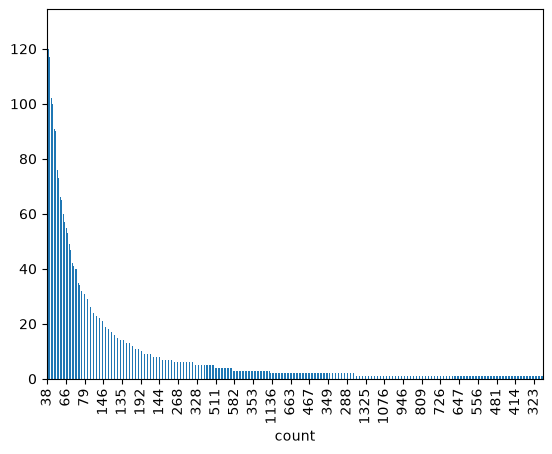

In [8]:
!pip install matplotlib
import matplotlib as plt

#display how many movies have x number of reviews for all movies
occurances = reviews['name'].value_counts() #number of reviews per movie
revCount = occurances.value_counts() #number of movies with x number of reviews

ax = revCount.plot(kind='bar')

ax.set_xticks(np.arange(0, len(revCount), 25))
ax.set_xticklabels(revCount.index[::25])

# plt.show()